In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Task 1 — Load and Understand the Dataset

In [3]:
df = pd.read_csv("penguins.csv")

In [4]:
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [5]:
df.tail()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009
343,Chinstrap,Dream,50.2,18.7,198.0,3775.0,female,2009


In [9]:
df.shape

(344, 8)

In [10]:
df.columns

Index(['species', 'island', 'bill_length_mm', 'bill_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex', 'year'],
      dtype='str')

In [11]:
df.dtypes

species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
year                   int64
dtype: object

In [12]:
df.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029070
std,5.459584,1.974793,14.061714,801.954536,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


In [13]:
df.describe(include='object')

C:\Users\KIRAN\AppData\Local\Temp\ipykernel_14728\87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,species,island,sex
count,344,344,333
unique,3,3,2
top,Adelie,Biscoe,male
freq,152,168,168


### Task 1 — Dataset Overview

The Palmer Penguins dataset contains **[number of rows] rows** and **[number of columns] columns**. It includes information about penguin species, islands, physical measurements, and sex.

The numerical summary provides information about the average, minimum, maximum, and distribution of the measurements. The categorical summary identifies the different categories and their most frequent values.

The dataset contains both numerical and categorical features, making it suitable for exploratory data analysis.

Task 2 — Identify and Handle Missing Values

In [14]:
df.isnull()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,True,True,True,True,True,False
4,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...
339,False,False,False,False,False,False,False,False
340,False,False,False,False,False,False,False,False
341,False,False,False,False,False,False,False,False
342,False,False,False,False,False,False,False,False


In [15]:
df.isnull().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

In [16]:
df.isnull().sum().sum()

np.int64(19)

In [17]:
total_missing = df.isnull().sum().sum()

total_cells = df.size

missing_percentage = (total_missing / total_cells) * 100

print("Total Missing Values:", total_missing)
print("Total Cells:", total_cells)
print("Missing Percentage:", missing_percentage, "%")

Total Missing Values: 19
Total Cells: 2752
Missing Percentage: 0.690406976744186 %


In [18]:
missing_report = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100
})

missing_report

,Missing Values,Missing Percentage
species,0,0.000000
island,0,0.000000
bill_length_mm,2,0.581395
bill_depth_mm,2,0.581395
flipper_length_mm,2,0.581395
body_mass_g,2,0.581395
sex,11,3.197674
year,0,0.000000


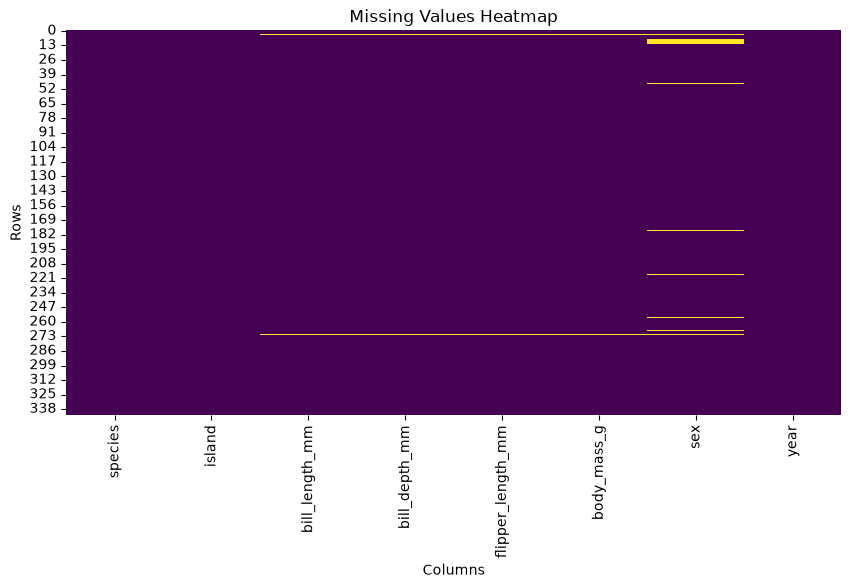

In [19]:
plt.figure(figsize=(10, 5))

sns.heatmap(df.isnull(), cbar=False, cmap='viridis')

plt.title("Missing Values Heatmap")
plt.xlabel("Columns")
plt.ylabel("Rows")

plt.show()

In [20]:
df.select_dtypes(include=np.number).columns

Index(['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g',
       'year'],
      dtype='str')

In [21]:
df.select_dtypes(include=np.number).median()

bill_length_mm         44.45
bill_depth_mm          17.30
flipper_length_mm     197.00
body_mass_g          4050.00
year                 2008.00
dtype: float64

In [22]:
df['body_mass_g'].fillna(df['body_mass_g'].median())

0      3750.0
1      3800.0
2      3250.0
3      4050.0
4      3450.0
        ...  
339    4000.0
340    3400.0
341    3775.0
342    4100.0
343    3775.0
Name: body_mass_g, Length: 344, dtype: float64

In [23]:
numerical_columns = df.select_dtypes(include=np.number).columns

for column in numerical_columns:
    df[column] = df[column].fillna(df[column].median())

In [25]:
categorical_columns = df.select_dtypes(include=['str', 'object']).columns

for column in categorical_columns:
    df[column] = df[column].fillna(df[column].mode()[0])

In [26]:
df.isnull().sum()

species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
year                 0
dtype: int64

Task 3 — Handling Duplicate Values

In [27]:
df.duplicated().sum()

np.int64(0)

In [28]:
df[df.duplicated()]

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year


In [29]:
duplicate_count = df.duplicated().sum()

print("Total Duplicate Rows:", duplicate_count)

Total Duplicate Rows: 0


In [30]:
df = df.drop_duplicates()

In [31]:
df.duplicated().sum()

np.int64(0)

Task 4 — Handling Inconsistent Categorical Data

In [32]:
categorical_columns = df.select_dtypes(include=['str', 'object']).columns

print(categorical_columns)

Index(['species', 'island', 'sex'], dtype='str')


In [33]:
for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].unique())


species:
<StringArray>
['Adelie', 'Gentoo', 'Chinstrap']
Length: 3, dtype: str

island:
<StringArray>
['Torgersen', 'Biscoe', 'Dream']
Length: 3, dtype: str

sex:
<StringArray>
['male', 'female']
Length: 2, dtype: str


In [34]:
for column in categorical_columns:
    df[column] = df[column].str.strip().str.lower()

In [35]:
for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].unique())


species:
<StringArray>
['adelie', 'gentoo', 'chinstrap']
Length: 3, dtype: str

island:
<StringArray>
['torgersen', 'biscoe', 'dream']
Length: 3, dtype: str

sex:
<StringArray>
['male', 'female']
Length: 2, dtype: str


Task 5 — Outlier Detection

In [36]:
numerical_columns = df.select_dtypes(include=np.number).columns

print(numerical_columns)

Index(['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g',
       'year'],
      dtype='str')


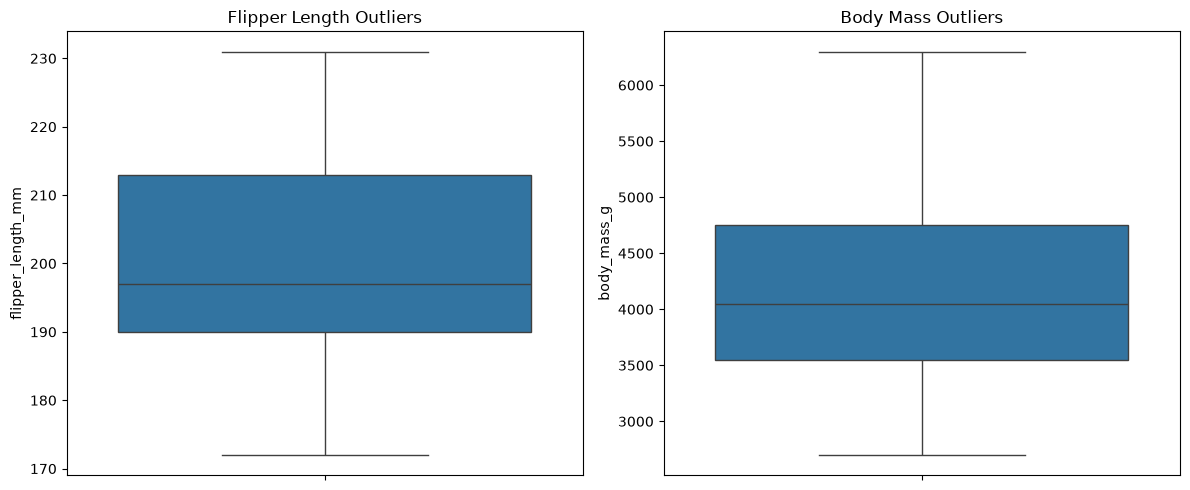

In [37]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=df['flipper_length_mm'])
plt.title("Flipper Length Outliers")

plt.subplot(1, 2, 2)
sns.boxplot(y=df['body_mass_g'])
plt.title("Body Mass Outliers")

plt.tight_layout()
plt.show()

In [38]:
columns_to_check = ['flipper_length_mm', 'body_mass_g']

for column in columns_to_check:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"\nColumn: {column}")
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Outliers:", len(outliers))


Column: flipper_length_mm
Q1: 190.0
Q3: 213.0
IQR: 23.0
Lower Bound: 155.5
Upper Bound: 247.5
Number of Outliers: 0

Column: body_mass_g
Q1: 3550.0
Q3: 4750.0
IQR: 1200.0
Lower Bound: 1750.0
Upper Bound: 6550.0
Number of Outliers: 0


Task 6 — Data Visualization

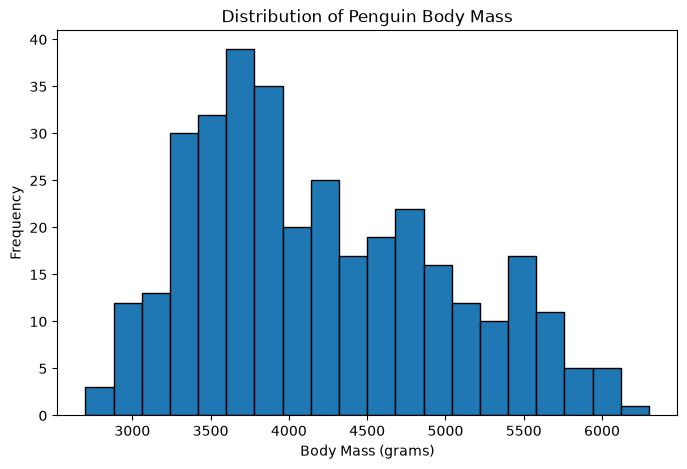

In [39]:
plt.figure(figsize=(8, 5))

plt.hist(df['body_mass_g'], bins=20, edgecolor='black')

plt.title("Distribution of Penguin Body Mass")
plt.xlabel("Body Mass (grams)")
plt.ylabel("Frequency")

plt.show()

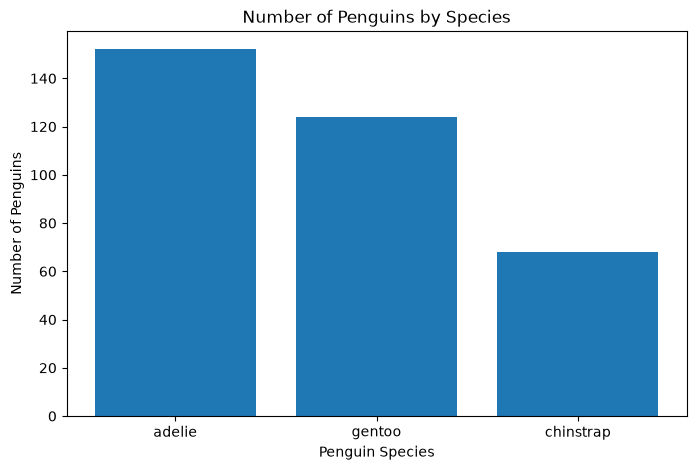

In [40]:
plt.figure(figsize=(8, 5))

species_counts = df['species'].value_counts()

plt.bar(species_counts.index, species_counts.values)

plt.title("Number of Penguins by Species")
plt.xlabel("Penguin Species")
plt.ylabel("Number of Penguins")

plt.show()

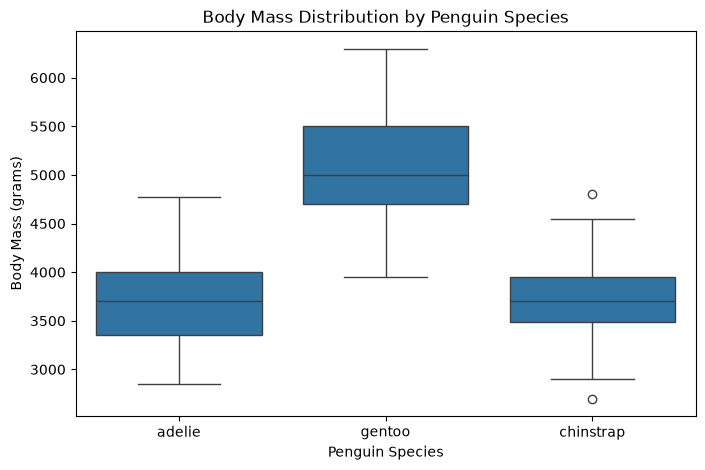

In [41]:
plt.figure(figsize=(8, 5))

sns.boxplot(x='species', y='body_mass_g', data=df)

plt.title("Body Mass Distribution by Penguin Species")
plt.xlabel("Penguin Species")
plt.ylabel("Body Mass (grams)")

plt.show()

In [42]:
correlation = df.select_dtypes(include=np.number).corr()

correlation

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
bill_length_mm,1.000000,-0.235000,0.655858,0.594925,0.054285
bill_depth_mm,-0.235000,1.000000,-0.583832,-0.471942,-0.060105
flipper_length_mm,0.655858,-0.583832,1.000000,0.871221,0.168954
body_mass_g,0.594925,-0.471942,0.871221,1.000000,0.042060
year,0.054285,-0.060105,0.168954,0.042060,1.000000


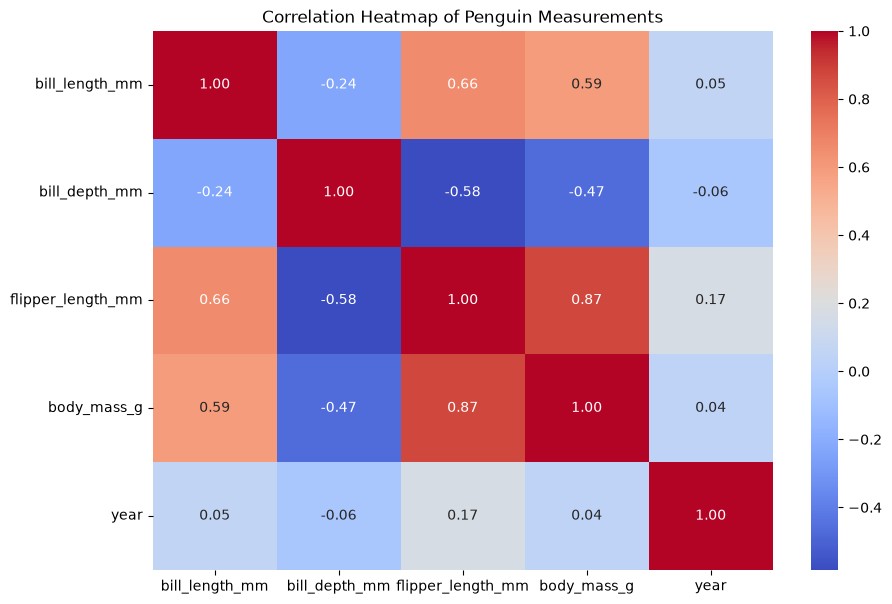

In [43]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap of Penguin Measurements")
plt.show()

Task 7 — Feature Engineering

In [44]:
df['bill_ratio'] = df['bill_length_mm'] / df['bill_depth_mm']

In [45]:
df[['bill_length_mm', 'bill_depth_mm', 'bill_ratio']].head()

,bill_length_mm,bill_depth_mm,bill_ratio
0,39.10,18.7,2.090909
1,39.50,17.4,2.270115
2,40.30,18.0,2.238889
3,44.45,17.3,2.569364
4,36.70,19.3,1.901554


Task 8 — Encoding Categorical Data

In [46]:
from sklearn.preprocessing import LabelEncoder

In [47]:
label_encoder = LabelEncoder()

df['species_encoded'] = label_encoder.fit_transform(df['species'])

In [48]:
df[['species', 'species_encoded']].head(10)

,species,species_encoded
0,adelie,0
1,adelie,0
2,adelie,0
3,adelie,0
4,adelie,0
5,adelie,0
6,adelie,0
7,adelie,0
8,adelie,0
9,adelie,0


In [49]:
df_encoded = pd.get_dummies(
    df,
    columns=['island'],
    dtype=int
)

In [50]:
df_encoded.filter(regex='^island_').head(10)

,island_biscoe,island_dream,island_torgersen
0,0,0,1
1,0,0,1
2,0,0,1
3,0,0,1
4,0,0,1
5,0,0,1
6,0,0,1
7,0,0,1
8,0,0,1
9,0,0,1


In [51]:
print(df_encoded.columns)

Index(['species', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm',
       'body_mass_g', 'sex', 'year', 'bill_ratio', 'species_encoded',
       'island_biscoe', 'island_dream', 'island_torgersen'],
      dtype='str')


Task 9 — Feature Scaling

In [52]:
from sklearn.preprocessing import MinMaxScaler

In [53]:
features = df[['bill_length_mm', 'flipper_length_mm']]

In [54]:
minmax_scaler = MinMaxScaler()

minmax_scaled = minmax_scaler.fit_transform(features)

minmax_df = pd.DataFrame(
    minmax_scaled,
    columns=['bill_length_scaled', 'flipper_length_scaled']
)

In [55]:
comparison = pd.concat(
    [features.reset_index(drop=True),
     minmax_df],
    axis=1
)

comparison.head()

,bill_length_mm,flipper_length_mm,bill_length_scaled,flipper_length_scaled
0,39.10,181.0,0.254545,0.152542
1,39.50,186.0,0.269091,0.237288
2,40.30,195.0,0.298182,0.389831
3,44.45,197.0,0.449091,0.423729
4,36.70,193.0,0.167273,0.355932


In [56]:
from sklearn.preprocessing import StandardScaler

In [57]:
standard_scaler = StandardScaler()

standard_scaled = standard_scaler.fit_transform(features)

standard_df = pd.DataFrame(
    standard_scaled,
    columns=['bill_length_standardized',
             'flipper_length_standardized']
)

In [58]:
standard_comparison = pd.concat(
    [features.reset_index(drop=True),
     standard_df],
    axis=1
)

standard_comparison.head()

,bill_length_mm,flipper_length_mm,bill_length_standardized,flipper_length_standardized
0,39.10,181.0,-0.887622,-1.420541
1,39.50,186.0,-0.814037,-1.063485
2,40.30,195.0,-0.666866,-0.420786
3,44.45,197.0,0.096581,-0.277964
4,36.70,193.0,-1.329133,-0.563608


In [59]:
print("Means:")
print(standard_df.mean())

print("\nStandard Deviations:")
print(standard_df.std())

Means:
bill_length_standardized      -7.435912e-16
flipper_length_standardized    2.065531e-16
dtype: float64

Standard Deviations:
bill_length_standardized       1.001457
flipper_length_standardized    1.001457
dtype: float64


Task 10 — Final Data Verification and Saving

In [60]:
print("Dataset Shape:", df_encoded.shape)

print("\nMissing Values:")
print(df_encoded.isnull().sum())

print("\nTotal Missing Values:", df_encoded.isnull().sum().sum())

print("\nDuplicate Rows:", df_encoded.duplicated().sum())

Dataset Shape: (344, 12)

Missing Values:
species              0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
year                 0
bill_ratio           0
species_encoded      0
island_biscoe        0
island_dream         0
island_torgersen     0
dtype: int64

Total Missing Values: 0

Duplicate Rows: 0


In [61]:
df_encoded.head()

,species,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year,bill_ratio,species_encoded,island_biscoe,island_dream,island_torgersen
0,adelie,39.10,18.7,181.0,3750.0,male,2007,2.090909,0,0,0,1
1,adelie,39.50,17.4,186.0,3800.0,female,2007,2.270115,0,0,0,1
2,adelie,40.30,18.0,195.0,3250.0,female,2007,2.238889,0,0,0,1
3,adelie,44.45,17.3,197.0,4050.0,male,2007,2.569364,0,0,0,1
4,adelie,36.70,19.3,193.0,3450.0,female,2007,1.901554,0,0,0,1


In [62]:
df_encoded.to_csv("penguins_cleaned.csv", index=False)

In [63]:
final_df = pd.read_csv("penguins_cleaned.csv")

print("Saved Dataset Shape:", final_df.shape)
final_df.head()

Saved Dataset Shape: (344, 12)


,species,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year,bill_ratio,species_encoded,island_biscoe,island_dream,island_torgersen
0,adelie,39.10,18.7,181.0,3750.0,male,2007,2.090909,0,0,0,1
1,adelie,39.50,17.4,186.0,3800.0,female,2007,2.270115,0,0,0,1
2,adelie,40.30,18.0,195.0,3250.0,female,2007,2.238889,0,0,0,1
3,adelie,44.45,17.3,197.0,4050.0,male,2007,2.569364,0,0,0,1
4,adelie,36.70,19.3,193.0,3450.0,female,2007,1.901554,0,0,0,1


In [ ]:
# Conclusion

In this assignment, Exploratory Data Analysis (EDA) and data preprocessing were performed on the Palmer Penguins dataset using Python. The main objective was to understand the dataset, identify data quality issues, clean the data, and prepare it for future machine learning tasks.

Initially, the dataset was loaded using Pandas, and its structure was examined using functions such as `head()`, `tail()`, `shape`, `dtypes`, and `describe()`. This helped in understanding the rows, columns, data types, and statistical properties of the dataset.

During missing-value analysis, missing entries were identified using Pandas. Numerical missing values were handled using median imputation because the median is less affected by extreme values than the mean. Categorical missing values were filled using the mode, which is the most frequently occurring category. A heatmap was also used to visualize missing values.

Duplicate records were checked using `duplicated()` and handled using `drop_duplicates()`. Categorical columns were examined for inconsistent formatting, and text values were standardized by removing extra spaces and converting them to lowercase.

Outliers were investigated in numerical features using boxplots and the Interquartile Range (IQR) method. Potential outliers were identified, but they were not automatically removed because unusual penguin measurements may represent genuine biological differences.

Four visualizations were created: a histogram to examine body mass distribution, a bar chart to compare penguin species, a boxplot to study body mass across species, and a correlation heatmap to explore relationships between numerical features.

Feature engineering was performed by creating a new feature called `bill_ratio`, calculated by dividing bill length by bill depth. Categorical variables were transformed using Label Encoding and One-Hot Encoding. Finally, Min-Max Scaling and StandardScaler were applied to numerical features to understand how different scaling techniques transform data.

At the end, the cleaned and transformed dataset was verified and saved as `penguins_cleaned.csv`.

Overall, this assignment improved my understanding of data exploration, data cleaning, visualization, feature engineering, encoding, and feature scaling. These preprocessing techniques are important steps in preparing reliable data for future machine learning applications.

In [ ]:
### Q1. Why is data preprocessing important before training an AI model?

Data preprocessing is important because raw data may contain missing values, duplicate records, inconsistent formats, and outliers. These problems can affect the accuracy and performance of an AI model. Preprocessing cleans and organizes the data so the model can learn more effectively and produce reliable results.

### Q2. What is the difference between missing values and duplicate records?

Missing values are entries where information is absent or unavailable in a dataset. Duplicate records are rows that contain the same information and appear more than once. Missing values can be handled through imputation or removal, while duplicate records can be identified and removed to avoid unnecessary repetition.

### Q3. Why is the median sometimes preferred over the mean when handling missing values?

The median is sometimes preferred because it is less affected by extremely high or low values (outliers). The mean can change significantly when extreme values are present, whereas the median represents the middle value and is more resistant to these changes. Therefore, median imputation is often suitable for numerical data containing outliers.

### Q4. What are outliers, and why should we not automatically remove them?

Outliers are data values that are unusually high or low compared with most other values in a dataset. We should not automatically remove them because they may represent genuine observations or natural variations rather than errors. Removing valid outliers could result in losing useful information and making the dataset less representative.

### Q5. What is the difference between Label Encoding and One-Hot Encoding?

Label Encoding assigns a numerical value to each unique category in a categorical column. For example, Adelie, Chinstrap, and Gentoo may be represented as 0, 1, and 2.

One-Hot Encoding creates separate binary columns for each category, using 1 to represent the presence of a category and 0 to represent its absence. Label Encoding is useful when numerical category labels are appropriate, while One-Hot Encoding is generally suitable for nominal categories that have no natural order.

### Q6. Why is feature scaling important for some machine learning algorithms?

Feature scaling is important because numerical features may have very different ranges. A feature with larger values can dominate calculations in some machine learning algorithms. Scaling brings features to comparable ranges and can improve the performance of algorithms such as K-Nearest Neighbors (KNN), Support Vector Machines (SVM), and algorithms that use gradient-based optimization.

### Q7. What problems could occur if we train a machine learning model on uncleaned data?

Training a machine learning model on uncleaned data can lead to inaccurate predictions, poor performance, and unreliable results. Missing values may cause errors, duplicate records may introduce bias, inconsistent categories may be treated as different values, and outliers may affect model calculations. Therefore, cleaning and preprocessing data are important before training an AI model.